# 06 · Reaction-diffusion: fronts and patterns

Add a reaction term to diffusion and the solution can organise itself: Fisher's equation produces a front that
invades at a speed fixed by the equation, and the Gray-Scott system produces spots and stripes from noise. These
problems also raise the method-of-lines question of *splitting*: diffusion is stiff and linear, reaction is
nonlinear but not stiff - so treat diffusion implicitly and reaction explicitly (IMEX), and the step is limited
by the reaction alone. This notebook measures the KPP front speed in one and two dimensions, compares BDF with
IMEX, and grows Gray-Scott patterns.

**What you will learn**
- measure a travelling-wave speed and recognise its slow approach to the KPP value
- split a problem into implicit diffusion and explicit reaction (IMEX)
- decide from the spectrum when an explicit method is the right tool
- integrate 2-D reaction-diffusion systems

**Before you start:** notebooks 02 and 05  ·  **Time:** about 60 min

In [1]:
try:                      # on Google Colab (or anywhere engmolines is missing): install it from GitHub
    import engmolines
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engmolines"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engmolines import problems as pr, integrators as ti, analysis, stiffness
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Fisher's travelling wave

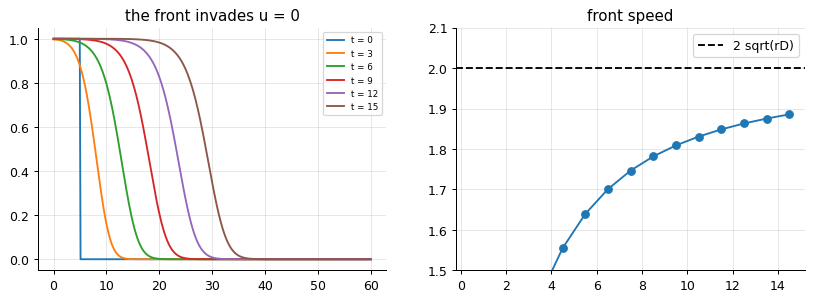

speed at the end 1.886, approaching 2 sqrt(rD) = 2.0 from below (Bramson: 2 - 3/(2t) + ...)


In [2]:
p = pr.fisher()
s = p.solve("bdf", 0.02, order=2, n_out=15)
pos = np.array([pr.front_position(p.x, y) for y in s.y])
speed = np.diff(pos) / np.diff(s.t)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for t, y in zip(s.t[::3], s.y[::3]):
    axes[0].plot(p.x, y, label=f"t = {t:.0f}")
axes[0].legend(fontsize=7); axes[0].set_title("the front invades u = 0")
axes[1].plot(0.5 * (s.t[1:] + s.t[:-1]), speed, "o-"); axes[1].axhline(p.params["speed"], color="k", ls="--", label="2 sqrt(rD)"); axes[1].legend(); axes[1].set_ylim(1.5, 2.1); axes[1].set_title("front speed")
plt.show()
print(f"speed at the end {speed[-1]:.3f}, approaching 2 sqrt(rD) = {p.params['speed']} from below (Bramson: 2 - 3/(2t) + ...)")

u_t = D u_xx + r u(1 − u) started from a step develops a front moving at the minimal speed 2√(rD), the
Kolmogorov-Petrovsky-Piskunov result: diffusion spreads the leading edge, growth amplifies it, and the balance
selects the speed. The convergence to 2 is slow - Bramson's correction is −3/(2t) - which the measured speeds
reproduce; a quick look at the first few values would report 1.85 and call it an error.

## IMEX: implicit diffusion, explicit reaction

In [3]:
lam = stiffness.spectrum(p.rhs, s.y[-1], band=(1, 1)); lam = lam[np.abs(lam) > 1e-9]
print(f"spectrum of the full system: {lam[0].real:.0f} to {lam[-1].real:+.3f}; RK4 limit {stiffness.explicit_step_limit(lam, 'rk4'):.4f}")
runs = {"BDF2 (fully implicit)": p.solve("bdf", 0.02, order=2, n_out=15),
        "IMEX CNAB2 (diffusion implicit, reaction explicit)": p.solve("imex", 0.02, n_out=15),
        "IMEX Euler": p.solve("imex", 0.02, n_out=15, order=1)}
for name, r in runs.items():
    print(f"{name:<52}: front at {pr.front_position(p.x, r.y[-1]):.3f}, Newton {r.newton_iterations}, Jacobians {r.jacobian_evaluations}")
big = p.solve("imex", 0.5, n_out=15, order=1, allow_failure=True)
print(f"IMEX Euler at h = 0.5 (the reaction's limit is about 2/r = 2): stable, but first order - the front lags at {pr.front_position(p.x, big.y[-1]):.2f}")

spectrum of the full system: -179 to +0.997; RK4 limit 0.0156


BDF2 (fully implicit)                               : front at 28.829, Newton 3030, Jacobians 1
IMEX CNAB2 (diffusion implicit, reaction explicit)  : front at 28.816, Newton 1500, Jacobians 2
IMEX Euler                                          : front at 28.760, Newton 1500, Jacobians 1


IMEX Euler at h = 0.5 (the reaction's limit is about 2/r = 2): stable, but first order - the front lags at 27.04


The IMEX methods treat the linear diffusion implicitly - one factorisation of the tridiagonal Jacobian, and a
Newton iteration that converges in a single step because the implicit part is linear - and the reaction
explicitly, so their step is limited by the reaction rate r, not by 4D/Δx²: even h = 0.5 is stable (though
first-order IMEX Euler is then inaccurate). For problems whose stiffness is linear and whose nonlinearity is
cheap, IMEX removes the nonlinear solve from the stiff part; its second-order variant (Crank-Nicolson for
diffusion, Adams-Bashforth for the reaction) matches BDF2 at half the Newton work.

## A circular front in two dimensions

front radius: [ 3.07  3.33  4.07  5.14  6.46  7.98  9.54 11.2  12.86]
radial speed: [0.257 0.74  1.07  1.321 1.517 1.563 1.663 1.661]  (planar speed 2; a front of radius R moves at 2 - D/R)


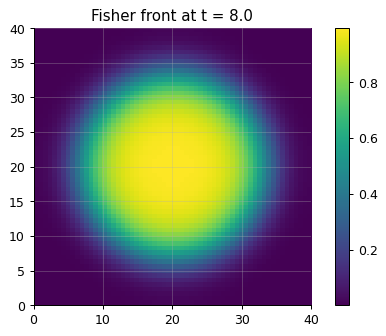

In [4]:
p2 = pr.fisher_2d(n=60)
s2 = p2.solve("bdf", 0.05, order=2, n_out=8)
rad = np.array([np.sqrt(np.mean(y > 0.5) * 40.0**2 / np.pi) for y in s2.y])
print("front radius:", np.round(rad, 2)); print("radial speed:", np.round(np.diff(rad) / np.diff(s2.t), 3), " (planar speed 2; a front of radius R moves at 2 - D/R)")
plt.imshow(s2.y[-1].reshape(p2.params["shape"]).T, origin="lower", extent=(0, 40, 0, 40), cmap="viridis"); plt.colorbar(); plt.title(f"Fisher front at t = {s2.t[-1]}"); plt.show()

In two dimensions the Jacobian has band n (the Kronecker structure of notebook 12) and BDF2 still needs one
Jacobian for the whole run. The circular front moves at the planar speed minus a curvature correction D/R,
so it accelerates towards 2 as it grows - the two-dimensional analogue of the slow approach seen in 1-D.

## Gray-Scott: patterns from noise

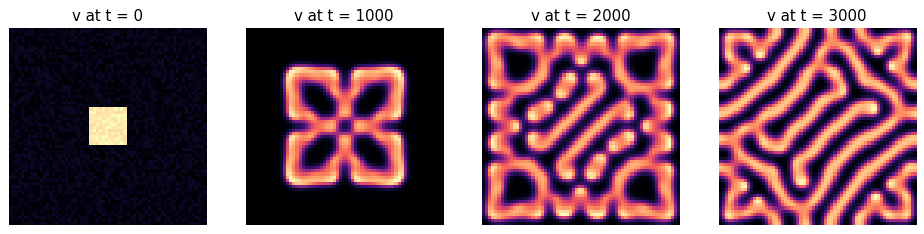

explicit RK4 with h = 1: 3000 steps; the reaction limits the step (diffusivities 2e-5 and 1e-5 give 4D/dx^2 = 0.33, so diffusion is NOT stiff here)


In [5]:
p = pr.gray_scott(n=64, F=0.037, k=0.06)
s = p.solve("rk4", 1.0, t_end=3000.0, n_out=3)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, t, y in zip(axes, s.t, s.y):
    ax.imshow(y[64 * 64 :].reshape(64, 64).T, origin="lower", cmap="magma"); ax.set_title(f"v at t = {t:.0f}"); ax.axis("off")
plt.show()
print(f"explicit RK4 with h = 1: {s.steps} steps; the reaction limits the step (diffusivities 2e-5 and 1e-5 give 4D/dx^2 = {4 * 2e-5 / (1 / 64)**2:.2f}, so diffusion is NOT stiff here)")

Gray-Scott's two species have tiny diffusivities and comparable reaction rates; the diffusive eigenvalues
(4D/Δx² ≈ 0.3) are no larger than the reaction's, so the system is not stiff and explicit RK4 with h = 1 is the
right tool - 3000 cheap steps rather than 3000 banded solves. Choosing the integrator starts with the spectrum,
not with habit. The spots that emerge from the perturbed seed are the classic Turing-type pattern of this
parameter pair.

## Inside the algorithm: one IMEX Euler step by hand

In [6]:
from engmolines import linalg as la
p1 = pr.fisher(); u = p1.y0.copy(); h = 0.02
A = la.from_banded(la.banded_jacobian(lambda w: p1.params["rhs_implicit"](0.0, w), u, 1, 1), 1, 1)   # the (linear) diffusion operator with its Neumann ghosts
rhs = u + h * p1.params["rhs_explicit"](0.0, u)          # explicit reaction
u_new = np.linalg.solve(np.eye(len(u)) - h * A, rhs)     # implicit diffusion: one linear solve, no Newton
lib = ti.imex(p1.params["rhs_explicit"], p1.params["rhs_implicit"], u, (0, h), h, band=(1, 1), order=1, n_out=1).y[-1]
print("one IMEX Euler step by hand vs library:", f"{np.max(np.abs(u_new - lib)):.1e}")

one IMEX Euler step by hand vs library: 7.3e-10


## Exercises
1. Measure the Fisher front speed on grids with dx = 0.3, 0.15, 0.075 and extrapolate the asymptotic speed at t = 15; compare with 2 and with Bramson's 2 - 3/(2t).
2. Change Gray-Scott to F = 0.03, k = 0.062 and to F = 0.025, k = 0.05 (worms, then chaos). Does explicit RK4 remain adequate? Confirm with the spectrum at a developed pattern.
3. **Implement it yourself:** write the IMEX CNAB2 step (Crank-Nicolson for diffusion, second-order Adams-Bashforth for the reaction) and reproduce the library's front position.